---
title: Measuring Distribution Distances
author: Mark Fuge
date: 'October 20 2025'
format:
    html:
        code-fold: true
        code-summary: "Show Code"
---


This notebook explores several ways of quantifying distances between one-dimensional probability distributions. We will contrast their mathematical definitions, visualize how they react to parameter changes, and compare the gradients that each metric produces. The goal is to build intuition for why the choice of divergence matters in optimization problems such as generative modeling or system identification. We will explore the following:

- Contrast forward KL, reverse KL, Jensen–Shannon divergence, Maximum Mean Discrepancy, and Wasserstein distance on simple families of distributions.
- Inspect how each distance responds to shifting the mean of a model Gaussian relative to a fixed target distribution.
- Visualize analytical or automatic-differentiation gradients to anticipate their effect on parameter updates.
- Experiment interactively with key hyperparameters (e.g., kernel bandwidth, mixture weights) to see how diagnostics change.

**Learning Objectives**

By the end of this chapter, you should be able to:

1. Explain why comparing distributions needs a notion of distance and which properties matter (symmetry, boundedness, behavior when supports do not overlap).
2. Contrast forward and reverse KL divergence and connect them to mode-covering versus mode-seeking behavior.
3. Explain why the Jensen-Shannon divergence is bounded and what that does to its gradients.
4. Explain maximum mean discrepancy (MMD) as a kernel-based distance and the role of the bandwidth.
5. Explain Wasserstein-2 as a transport cost and choose a distance for a modeling task from its gradient behavior.

In [1]:
# Setup and shared imports
from __future__ import annotations

import math
from dataclasses import dataclass
from typing import Callable, Dict, Tuple

import numpy as np
import torch
from matplotlib import pyplot as plt
from matplotlib.gridspec import GridSpec

import seaborn as sns

sns.set_context("talk")

import ipywidgets as widgets
from IPython.display import display

# Ensure reproducibility for sampling-based diagnostics
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")
DEFAULT_DTYPE = torch.float64

In [2]:
## Shared Distribution Utilities
# We will represent each distribution by two callables:
# - `pdf(x)` returning the probability density evaluated on a 1D tensor `x`.
# - `sample(n, base_noise)` producing differentiable samples (re-using base noise when we need gradients).

# To keep gradients tractable, we lean on reparameterizations for Gaussians and deterministic mixtures of Gaussians. For numerical integrals we discretize the domain on a dense grid.

# Dense grid for numerical integration (wide enough that a model Gaussian with |mu| up to 15 stays on it);
# density plots are clipped to PLOT_XLIM.
GRID_X = torch.linspace(-20.0, 20.0, 8192, dtype=DEFAULT_DTYPE, device=device)
PLOT_XLIM = (-6.0, 6.0)
DX = GRID_X[1] - GRID_X[0]
EPS = torch.tensor(1e-12, dtype=DEFAULT_DTYPE, device=device)


def gaussian_pdf_torch(x: torch.Tensor, mean: torch.Tensor | float, std: torch.Tensor | float) -> torch.Tensor:
    """Evaluate the Gaussian pdf on `x` using broadcasted parameters."""
    mean_t = torch.as_tensor(mean, dtype=DEFAULT_DTYPE, device=device)
    std_t = torch.as_tensor(std, dtype=DEFAULT_DTYPE, device=device)
    var = std_t ** 2
    norm_const = 1.0 / torch.sqrt(2.0 * math.pi * var)
    z = (x - mean_t) ** 2 / (2.0 * var)
    return norm_const * torch.exp(-z)


def gaussian_log_pdf_torch(x: torch.Tensor, mean: torch.Tensor | float, std: torch.Tensor | float) -> torch.Tensor:
    """Log of the Gaussian pdf, evaluated directly so that far tails do not underflow to zero."""
    mean_t = torch.as_tensor(mean, dtype=DEFAULT_DTYPE, device=device)
    std_t = torch.as_tensor(std, dtype=DEFAULT_DTYPE, device=device)
    return -0.5 * ((x - mean_t) / std_t) ** 2 - torch.log(std_t) - 0.5 * math.log(2.0 * math.pi)


def uniform_pdf_torch(x: torch.Tensor, low: float, high: float) -> torch.Tensor:
    low_t = torch.as_tensor(low, dtype=DEFAULT_DTYPE, device=device)
    high_t = torch.as_tensor(high, dtype=DEFAULT_DTYPE, device=device)
    inside = (x >= low_t) & (x <= high_t)
    return inside.to(DEFAULT_DTYPE) / (high_t - low_t + EPS)


def gaussian_mixture_pdf_torch(
    x: torch.Tensor,
    means: torch.Tensor,
    stds: torch.Tensor,
    weights: torch.Tensor,
) -> torch.Tensor:
    comps = [w * gaussian_pdf_torch(x, m, s) for w, m, s in zip(weights, means, stds)]
    return torch.stack(comps, dim=0).sum(dim=0)


@dataclass(frozen=True)
class DistributionSpec:
    name: str
    pdf: Callable[[torch.Tensor], torch.Tensor]
    sampler: Callable[[int, torch.Tensor | None], torch.Tensor]
    metadata: Dict[str, float]


def make_gaussian(mean: float = 0.0, std: float = 1.0) -> DistributionSpec:
    mean_t = torch.tensor(mean, dtype=DEFAULT_DTYPE, device=device)
    std_t = torch.tensor(std, dtype=DEFAULT_DTYPE, device=device)

    def _pdf(x: torch.Tensor) -> torch.Tensor:
        return gaussian_pdf_torch(x, mean_t, std_t)

    def _sample(n: int, base_noise: torch.Tensor | None = None) -> torch.Tensor:
        eps = torch.randn(n, dtype=DEFAULT_DTYPE, device=device) if base_noise is None else base_noise
        return mean_t + std_t * eps

    meta = {"mean": float(mean), "std": float(std)}
    return DistributionSpec(name=f"Gaussian(μ={mean:.2f}, σ={std:.2f})", pdf=_pdf, sampler=_sample, metadata=meta)


def make_uniform(low: float = -2.0, high: float = 2.0) -> DistributionSpec:
    low_t = torch.tensor(low, dtype=DEFAULT_DTYPE, device=device)
    high_t = torch.tensor(high, dtype=DEFAULT_DTYPE, device=device)

    def _pdf(x: torch.Tensor) -> torch.Tensor:
        return uniform_pdf_torch(x, float(low_t), float(high_t))

    def _sample(n: int, base_noise: torch.Tensor | None = None) -> torch.Tensor:
        if base_noise is None:
            base_noise = torch.rand(n, dtype=DEFAULT_DTYPE, device=device)
        return low_t + (high_t - low_t) * base_noise

    meta = {"low": float(low), "high": float(high)}
    return DistributionSpec(name=f"Uniform[{low:.1f}, {high:.1f}]", pdf=_pdf, sampler=_sample, metadata=meta)


def make_gaussian_mixture(
    means: Tuple[float, float] = (-2.0, 2.0),
    stds: Tuple[float, float] = (0.6, 0.6),
    weights: Tuple[float, float] = (0.5, 0.5),
) -> DistributionSpec:
    means_t = torch.tensor(means, dtype=DEFAULT_DTYPE, device=device)
    stds_t = torch.tensor(stds, dtype=DEFAULT_DTYPE, device=device)
    weights_t = torch.tensor(weights, dtype=DEFAULT_DTYPE, device=device)
    weights_t = weights_t / weights_t.sum()

    def _pdf(x: torch.Tensor) -> torch.Tensor:
        return gaussian_mixture_pdf_torch(x, means_t, stds_t, weights_t)

    def _sample(n: int, base_noise: torch.Tensor | None = None) -> torch.Tensor:
        # `base_noise` is standard-normal noise shared with the model (see sample_with_matching_noise);
        # the component of each sample is assigned deterministically in the mixture proportions.
        eps = torch.randn(n, dtype=DEFAULT_DTYPE, device=device) if base_noise is None else base_noise
        cumulative = torch.cumsum(weights_t, dim=0)
        u = torch.linspace(0.0, 1.0, n, dtype=DEFAULT_DTYPE, device=device)
        choices = torch.clamp(torch.bucketize(u, cumulative), max=len(means_t) - 1)
        return means_t[choices] + stds_t[choices] * eps

    meta = {
        "means": tuple(float(m) for m in means),
        "stds": tuple(float(s) for s in stds),
        "weights": tuple(float(w) for w in weights),
    }
    desc = ", ".join([f"μ={m:.1f}" for m in means])
    return DistributionSpec(name=f"Gaussian Mixture ({desc})", pdf=_pdf, sampler=_sample, metadata=meta)

In [3]:
# Common plotting helpers
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True})


def plot_distribution_pair(
    grid: torch.Tensor,
    target_pdf: torch.Tensor,
    model_pdf: torch.Tensor,
    title: str,
    target_label: str = "Target",
    model_label: str = "Model",
) -> None:
    fig, ax = plt.subplots()
    ax.plot(grid.cpu().numpy(), target_pdf.cpu().numpy(), label=target_label, linewidth=2)
    ax.plot(grid.cpu().numpy(), model_pdf.cpu().numpy(), label=model_label, linestyle="--", linewidth=2)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("Density")
    ax.set_xlim(*PLOT_XLIM)
    ax.legend()
    plt.show()


def plot_metric_and_gradient(
    mu_values: np.ndarray,
    metric_values: np.ndarray,
    gradient_values: np.ndarray,
    metric_name: str,
    target_desc: str,
) -> None:
    fig = plt.figure(figsize=(10, 5))
    gs = GridSpec(1, 2, figure=fig)
    ax_metric = fig.add_subplot(gs[0, 0])
    ax_grad = fig.add_subplot(gs[0, 1])

    ax_metric.plot(mu_values, metric_values, color="tab:blue", linewidth=2)
    ax_metric.set_title(f"{metric_name} vs. μ")
    ax_metric.set_xlabel("Model mean μ")
    ax_metric.set_ylabel(metric_name)

    ax_grad.plot(mu_values, gradient_values, color="tab:red", linewidth=2)
    ax_grad.axhline(0.0, color="black", linestyle=":", linewidth=1)
    ax_grad.set_title(f"Gradient d({metric_name})/dμ")
    ax_grad.set_xlabel("Model mean μ")
    ax_grad.set_ylabel("Gradient")

    fig.suptitle(f"{metric_name} against {target_desc}")
    fig.tight_layout()
    plt.show()


def evaluate_metric_curve(
    mu_values: np.ndarray,
    metric_fn: Callable[[torch.Tensor], torch.Tensor],
) -> Tuple[np.ndarray, np.ndarray]:
    metrics = []
    grads = []
    for mu in mu_values:
        mu_t = torch.tensor(mu, dtype=DEFAULT_DTYPE, device=device, requires_grad=True)
        metric = metric_fn(mu_t)
        grad = torch.autograd.grad(metric, mu_t)[0]
        metrics.append(metric.detach().cpu().item())
        grads.append(grad.detach().cpu().item())
    return np.array(metrics), np.array(grads)


def maybe_display(widget: widgets.Widget | None) -> None:
    if widget is None:
        print("ipywidgets not available in this environment. Install ipywidgets to enable interactivity.")
    else:
        display(widget)

In [4]:
# Define canonical target distributions used throughout the notebook
TARGETS: Dict[str, DistributionSpec] = {
    "gaussian": make_gaussian(mean=0.0, std=1.0),
    "wide_gaussian": make_gaussian(mean=0.0, std=1.8),
    "uniform": make_uniform(low=-3.0, high=3.0),
    "gaussian_mixture": make_gaussian_mixture(means=(-2.5, 2.5), stds=(0.6, 0.6), weights=(0.35, 0.65)),
}

#TARGETS

## A Toy Example: Comparing Two Gaussians
We will compare a *target* distribution $p(x)$ against a *model* distribution $q_\mu(x)$ whose mean $\mu$ we can adjust. Unless stated otherwise, the target will be the standard normal distribution. You can change that later to a uniform or a bimodal mixture to reveal different behaviors. Our baseline parameterization will keep the model standard deviation fixed at $\sigma_q = 1$, although you can change this if you like.

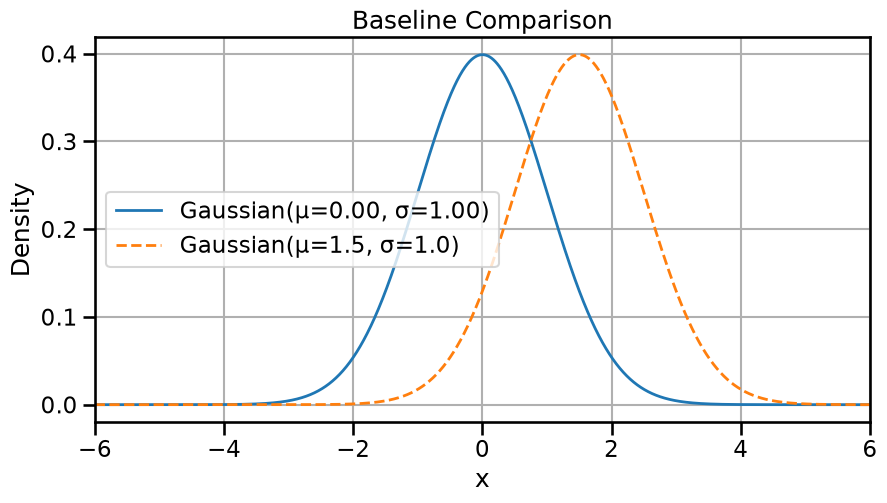

In [5]:
# Baseline visualization: standard normal target vs. shifted model Gaussian
TARGET = TARGETS["gaussian"]
MODEL_STD = torch.tensor(1.0, dtype=DEFAULT_DTYPE, device=device)
MU_BASE = torch.tensor(1.5, dtype=DEFAULT_DTYPE, device=device)

with torch.no_grad():
    target_pdf = TARGET.pdf(GRID_X)
    model_pdf = gaussian_pdf_torch(GRID_X, MU_BASE, MODEL_STD)

plot_distribution_pair(GRID_X, target_pdf, model_pdf, title="Baseline Comparison", target_label=TARGET.name, model_label=f"Gaussian(μ={MU_BASE.item():.1f}, σ=1.0)")

## Kullback–Leibler (KL) Divergence
Forward KL divergence compares how much mass the target distribution assigns relative to the model: 
$$
\mathrm{KL}(p\,\parallel\,q) = \int p(x) \log \frac{p(x)}{q(x)}\,dx.
$$
Because it integrates expectations under $p$, it heavily penalizes situations where $q(x)$ is small while $p(x)$ is large, even if the model allocates extra mass elsewhere.

### Analytical Gradient for Gaussian vs. Gaussian
For $p = \mathcal{N}(\mu_p, \sigma_p^2)$ and $q = \mathcal{N}(\mu, \sigma_q^2)$, forward KL admits a closed form:
$$
\mathrm{KL}(p\,\parallel\,q) = \log \frac{\sigma_q}{\sigma_p} + \frac{\sigma_p^2 + (\mu_p - \mu)^2}{2\sigma_q^2} - \frac{1}{2}.
$$
Differentiating w.r.t. the model mean gives
$$
\frac{\partial}{\partial \mu} \mathrm{KL}(p\,\parallel\,q) = \frac{\mu - \mu_p}{\sigma_q^2},
$$
which pushes $\mu$ directly toward $\mu_p$. We will evaluate the integral numerically to keep the pipeline consistent when we later switch to mixtures.

In [6]:
# Forward and reverse KL implementations using numerical integration
_target_pdf_cache: Dict[str, torch.Tensor] = {}


def get_target_pdf(spec: DistributionSpec) -> torch.Tensor:
    if spec.name not in _target_pdf_cache:
        with torch.no_grad():
            _target_pdf_cache[spec.name] = spec.pdf(GRID_X).detach()
    return _target_pdf_cache[spec.name]


def forward_kl(mu: torch.Tensor, target: DistributionSpec, model_std: float = 1.0) -> torch.Tensor:
    p_pdf = get_target_pdf(target)
    log_q = gaussian_log_pdf_torch(GRID_X, mu, model_std)
    integrand = p_pdf * (torch.log(p_pdf + EPS) - log_q)
    return torch.trapz(integrand, GRID_X)


def reverse_kl(mu: torch.Tensor, target: DistributionSpec, model_std: float = 1.0) -> torch.Tensor:
    p_pdf = get_target_pdf(target)
    log_q = gaussian_log_pdf_torch(GRID_X, mu, model_std)
    q_pdf = torch.exp(log_q)
    integrand = q_pdf * (log_q - torch.log(p_pdf + EPS))
    return torch.trapz(integrand, GRID_X)

Now let's look at how the forward KL behaves as the model mean $\mu$ shifts away from the target mean $\mu_p = 0$. We will plot the KL divergence, and its gradient, as we shift the model mean from -15 to 15. What do you notice about the behavior of the KL Divergence and it's gradient?

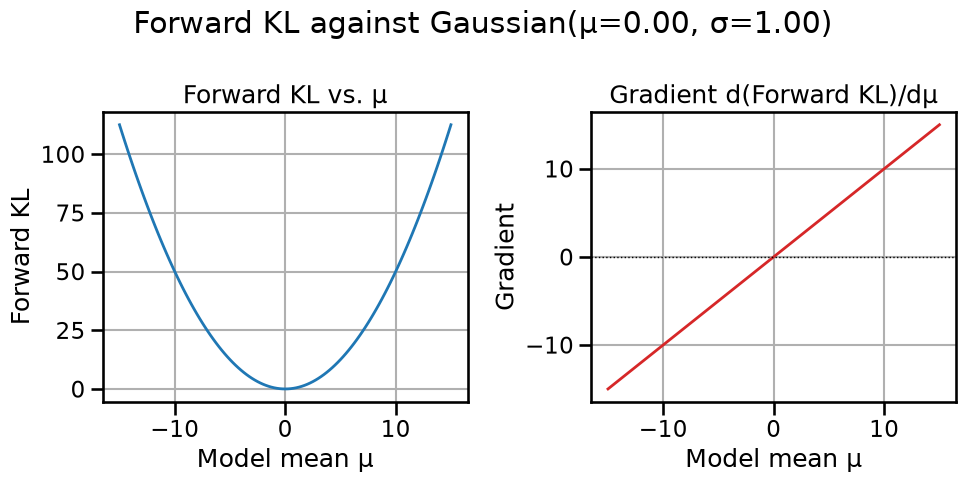

In [7]:
#| code-fold: false
# Forward KL distance curve for standard normal target
##### Change the following to see what happens #######
# (The integrals run over the grid GRID_X = [-20, 20], so keep |mu| below about 15:
#  a model centered much further out falls off the grid and the numbers stop meaning anything.)
mu_values = np.linspace(-15.0, 15.0, 121)
model_std = 1.0
####################################

forward_metrics, forward_grads = evaluate_metric_curve(
    mu_values,
    lambda mu: forward_kl(mu, TARGETS["gaussian"], model_std=model_std),
)
plot_metric_and_gradient(mu_values, forward_metrics, forward_grads, metric_name="Forward KL", target_desc=TARGETS["gaussian"].name)

::: {.callout-tip appearance="default"}
### Experiment: Forward KL on Gaussian Targets
- What happens to both the KL Divergence and its gradient when the model mean is close to the target mean? What about when it is far away? Why is this?
- How would the curve change if we widened the model variance? Try modifying `model_std` in the code cell above and re-running it.
- In the interactive explorer below, switch the target from the standard normal to the wide Gaussian, the uniform and the mixture. Which panels change and which do not, and why?
:::


Below what we will do is now go from comparing two Gaussians to comparing the KL Divergence of a Gaussian to several other target distributions. Before we do this though, let us consider how our above simplified equation for the KL divergence changes. Against a Gaussian model $q(x) = \mathcal{N}(x;\, \mu, \sigma_q^2)$ the forward KL has, for *any* target $p$,
$$
\mathrm{KL}(p\,\parallel\,q) = -H(p) + \log\!\left(\sigma_q\sqrt{2\pi}\right) + \frac{\mathrm{Var}_p[x] + \left(\mathbb{E}_p[x] - \mu\right)^2}{2\sigma_q^2},
$$
because $\mathbb{E}_p[-\log q(x)]$ only involves the first two moments of $p$ (and $H(p)$ is the entropy of the target, a constant). The curve against $\mu$ and its gradient $\partial\,\mathrm{KL}/\partial\mu = (\mu - \mathbb{E}_p[x])/\sigma_q^2$ therefore see the target only through its mean, and since all four targets have mean zero, switching the target in the explorer moves the $\mu$ curve up or down but changes neither its shape nor its gradient. The target's variance and entropy only add a constant, which is what moves the curve up or down. They would matter if we also adjusted the model width: setting the derivative with respect to $\sigma_q$ to zero gives the best width $\sigma_q^2 = \mathrm{Var}_p[x] + (\mu - \mathbb{E}_p[x])^2$. This is exactly why we say that the forward KL "cannot see shape": the best Gaussian under forward KL is always one that matches the moments of the target distribution, whether the target is a uniform or a bimodal mixture or something else. The reverse KL behaves very differently on the bimodal target, as the next section shows.

In [ ]:
# Interactive widget for forward KL
if widgets is None:
    maybe_display(None)
else:
    target_dropdown = widgets.Dropdown(
        options=[(spec.name, key) for key, spec in TARGETS.items()],
        value="gaussian",
        description="Target",
        style={"description_width": "initial"},
    )
    mu_slider = widgets.FloatSlider(value=0.0, min=-15.0, max=15.0, step=0.5, description="μ")
    std_slider = widgets.FloatSlider(value=1.0, min=0.4, max=2.5, step=0.1, description="σ_q")
    output = widgets.Output()

    def target_mean_and_variance(spec: DistributionSpec) -> Tuple[float, float]:
        """Mean and variance of a target, integrated numerically on the grid."""
        p_pdf = get_target_pdf(spec)
        mean = torch.trapz(GRID_X * p_pdf, GRID_X).item()
        variance = torch.trapz((GRID_X - mean) ** 2 * p_pdf, GRID_X).item()
        return mean, variance

    def _update_forward_kl(*_):
        with output:
            output.clear_output(wait=True)
            target = TARGETS[target_dropdown.value]
            mu_val = torch.tensor(mu_slider.value, dtype=DEFAULT_DTYPE, device=device, requires_grad=True)
            std_val = float(std_slider.value)
            kl_value = forward_kl(mu_val, target, model_std=std_val)
            grad = torch.autograd.grad(kl_value, mu_val)[0].detach().cpu().item()
            target_pdf = get_target_pdf(target)
            model_pdf = gaussian_pdf_torch(GRID_X, mu_slider.value, std_val)

            mu_values = np.linspace(mu_slider.min, mu_slider.max, 181)
            metrics_curve, grads_curve = evaluate_metric_curve(
                mu_values,
                lambda mu: forward_kl(mu, target, model_std=std_val),
            )

            target_mean, target_var = target_mean_and_variance(target)

            grid_np = GRID_X.cpu().numpy()
            target_np = target_pdf.cpu().numpy()
            model_np = model_pdf.cpu().numpy()

            # Densities on the left (spanning both rows); the KL curve and its gradient stacked on the right
            fig = plt.figure(figsize=(14, 8))
            gs = GridSpec(2, 2, figure=fig)
            axes = [fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])]

            axes[0].plot(grid_np, target_np, label=target.name, linewidth=2)
            axes[0].plot(grid_np, model_np, label=f"Model μ={mu_slider.value:.1f}, σ={std_val:.1f}", linestyle="--", linewidth=2)
            axes[0].set_title("Density comparison")
            axes[0].set_xlabel("x")
            axes[0].set_ylabel("Density")
            axes[0].set_xlim(*PLOT_XLIM)
            axes[0].legend(loc="upper left", fontsize=11)

            axes[1].plot(mu_values, metrics_curve, color="tab:blue", linewidth=2)
            axes[1].axvline(mu_slider.value, color="black", linestyle=":")
            axes[1].scatter([mu_slider.value], [kl_value.detach().cpu().item()], color="tab:blue")
            axes[1].set_title(f"Forward KL vs. μ at σ_q = {std_val:.1f}")
            axes[1].set_xlabel("Model mean μ")
            axes[1].set_ylabel("Forward KL")

            axes[2].plot(mu_values, grads_curve, color="tab:red", linewidth=2)
            axes[2].axhline(0.0, color="black", linestyle=":")
            axes[2].axvline(mu_slider.value, color="black", linestyle=":")
            axes[2].scatter([mu_slider.value], [grad], color="tab:red")
            axes[2].set_title("Gradient d(KL)/dμ")
            axes[2].set_xlabel("Model mean μ")
            axes[2].set_ylabel("Gradient")


            fig.suptitle(
                f"Forward KL = {kl_value.detach().cpu().item():.3f} | Gradient = {grad:.3f} | "
                f"target mean = {target_mean:.2f}, target variance = {target_var:.2f}",
                fontsize=14,
            )
            fig.tight_layout()
            plt.show()

    for control in (target_dropdown, mu_slider, std_slider):
        control.observe(_update_forward_kl, names="value")

    _update_forward_kl()
    maybe_display(widgets.VBox([widgets.HTML("<h4>Interactive Forward KL Explorer</h4>"), target_dropdown, mu_slider, std_slider, output]))

### Forward vs. Reverse KL on a Bimodal Target
Reverse KL, $\mathrm{KL}(q\,\parallel\,p)$, prefers to avoid regions where the model would place mass but the target does not. On multimodal targets this often leads to *mode seeking*: the optimizer chooses one mode to cover while ignoring others.

#### Mathematical Overview
The reverse KL is defined as
$$
\mathrm{KL}(q\,\parallel\,p) = \int q(x) \log \frac{q(x)}{p(x)}\,dx,
$$
so the expectation is taken under the model distribution $q$. If $q(x)$ places mass where $p(x)$ is negligible, the logarithm term explodes and strongly penalizes those regions. Conversely, areas where $p$ has mass but $q$ does not contribute nothing, which is why the optimizer can collapse onto a single mode when matching multimodal targets.

Let us compare the two on a mixture of Gaussians.

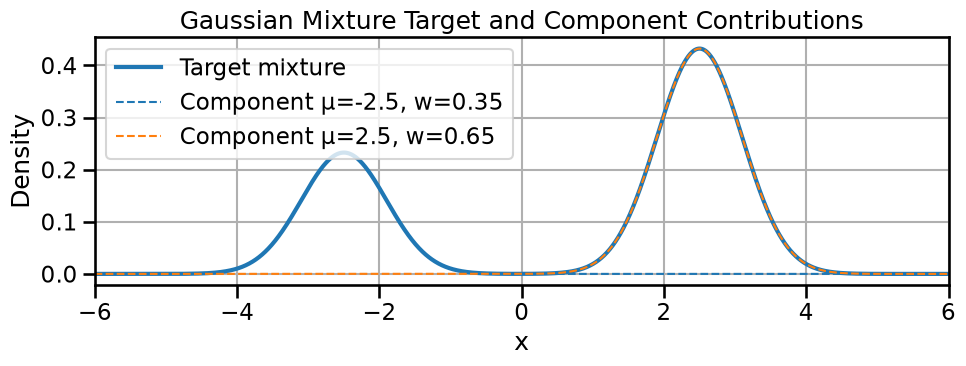

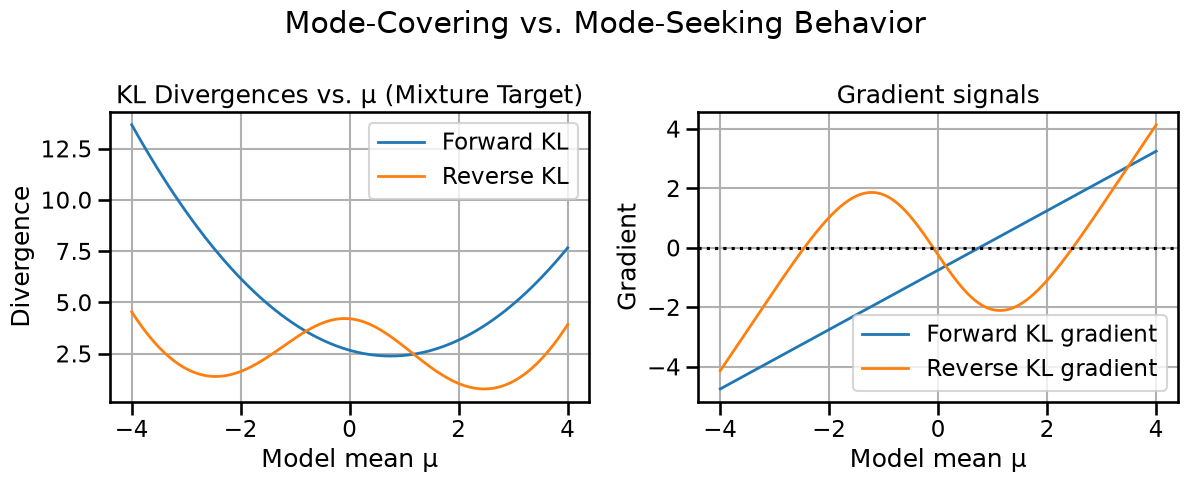

In [9]:
# Forward vs. reverse KL on a bimodal target
mixture_target = TARGETS["gaussian_mixture"]
component_means = mixture_target.metadata.get("means", (-2.5, 2.5))
component_stds = mixture_target.metadata.get("stds", (0.6, 0.6))
component_weights = mixture_target.metadata.get("weights", (0.5, 0.5))

with torch.no_grad():
    mixture_pdf = mixture_target.pdf(GRID_X).cpu().numpy()
    component_curves = []
    for mean, std, weight in zip(component_means, component_stds, component_weights):
        component_pdf = weight * gaussian_pdf_torch(GRID_X, mean, std)
        component_curves.append((mean, weight, component_pdf.cpu().numpy()))

grid_np = GRID_X.cpu().numpy()
fig_density, ax_density = plt.subplots(figsize=(10, 4))
ax_density.plot(grid_np, mixture_pdf, label="Target mixture", linewidth=3, color="tab:blue")
for mean, weight, comp_pdf in component_curves:
    ax_density.plot(
        grid_np,
        comp_pdf,
        linestyle="--",
        linewidth=1.5,
        label=f"Component μ={mean:.1f}, w={weight:.2f}",
    )
ax_density.set_title("Gaussian Mixture Target and Component Contributions")
ax_density.set_xlabel("x")
ax_density.set_ylabel("Density")
ax_density.set_xlim(*PLOT_XLIM)
ax_density.legend()
fig_density.tight_layout()
plt.show()

mu_values = np.linspace(-4.0, 4.0, 161)
forward_metrics_mix, forward_grads_mix = evaluate_metric_curve(
    mu_values,
    lambda mu: forward_kl(mu, mixture_target, model_std=1.0),
)
reverse_metrics_mix, reverse_grads_mix = evaluate_metric_curve(
    mu_values,
    lambda mu: reverse_kl(mu, mixture_target, model_std=1.0),
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
axes[0].plot(mu_values, forward_metrics_mix, label="Forward KL", linewidth=2)
axes[0].plot(mu_values, reverse_metrics_mix, label="Reverse KL", linewidth=2)
axes[0].set_title("KL Divergences vs. μ (Mixture Target)")
axes[0].set_xlabel("Model mean μ")
axes[0].set_ylabel("Divergence")
axes[0].legend()

axes[1].plot(mu_values, forward_grads_mix, label="Forward KL gradient", linewidth=2)
axes[1].plot(mu_values, reverse_grads_mix, label="Reverse KL gradient", linewidth=2)
axes[1].axhline(0.0, color="black", linestyle=":")
axes[1].set_title("Gradient signals")
axes[1].set_xlabel("Model mean μ")
axes[1].set_ylabel("Gradient")
axes[1].legend()

fig.suptitle("Mode-Covering vs. Mode-Seeking Behavior")
fig.tight_layout()
plt.show()


::: {.callout-tip appearance="default"}
### Reflection: Mode Covering vs. Mode Seeking
- Why does the forward KL gradient stay non-zero even between the two modes?  
- Identify the regions where the reverse KL gradient vanishes. How does that explain a model that only tracks one mode? 
:::


## Jensen–Shannon Divergence
The Jensen–Shannon (JS) divergence symmetrizes KL by averaging the two distributions: $m(x) = \tfrac{1}{2}(p(x)+q(x))$. It stays finite even when supports do not match and is bounded between 0 and $\log 2$.

### Mathematical Formulation
$$
\mathrm{JS}(p, q) = \tfrac{1}{2} \mathrm{KL}(p\,\parallel\,m) + \tfrac{1}{2} \mathrm{KL}(q\,\parallel\,m), \quad m = \tfrac{1}{2}(p + q).
$$
We will compute JS numerically on the same grid. Autograd gives us gradients through the logarithms as long as we keep everything in PyTorch tensors.

In [10]:
#| code-fold: false
def jensen_shannon(mu: torch.Tensor, target: DistributionSpec, model_std: float = 1.0) -> torch.Tensor:
    p_pdf = get_target_pdf(target)
    q_pdf = gaussian_pdf_torch(GRID_X, mu, model_std)
    m_pdf = 0.5 * (p_pdf + q_pdf)
    term_p = p_pdf * torch.log((p_pdf + EPS) / (m_pdf + EPS))
    term_q = q_pdf * torch.log((q_pdf + EPS) / (m_pdf + EPS))
    return 0.5 * torch.trapz(term_p, GRID_X) + 0.5 * torch.trapz(term_q, GRID_X)

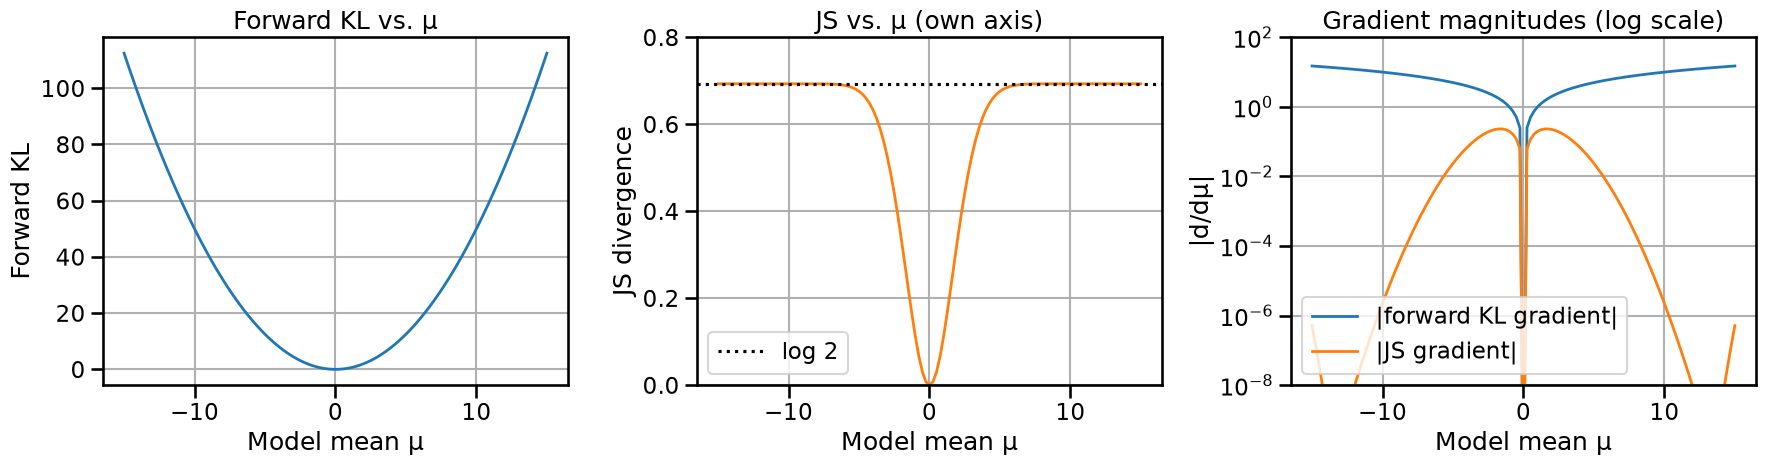

In [11]:
# JS divergence vs. μ for Gaussian target compared to forward KL
# (keep |mu| below about 15: the integrals only cover GRID_X = [-20, 20])
mu_values = np.linspace(-15.0, 15.0, 121)
js_metrics, js_grads = evaluate_metric_curve(
    mu_values,
    lambda mu: jensen_shannon(mu, TARGETS["gaussian"], model_std=1.0),
)

# JS is bounded by log 2, so it gets its own axis; the gradients are compared by magnitude on a log scale
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)
axes[0].plot(mu_values, forward_metrics, color="tab:blue", linewidth=2)
axes[0].set_title("Forward KL vs. μ")
axes[0].set_xlabel("Model mean μ")
axes[0].set_ylabel("Forward KL")

axes[1].plot(mu_values, js_metrics, color="tab:orange", linewidth=2)
axes[1].axhline(math.log(2.0), color="black", linestyle=":", label="log 2")
axes[1].set_ylim(0.0, 0.8)
axes[1].set_title("JS vs. μ (own axis)")
axes[1].set_xlabel("Model mean μ")
axes[1].set_ylabel("JS divergence")
axes[1].legend()

axes[2].semilogy(mu_values, np.maximum(np.abs(forward_grads), 1e-12), color="tab:blue", linewidth=2, label="|forward KL gradient|")
axes[2].semilogy(mu_values, np.maximum(np.abs(js_grads), 1e-12), color="tab:orange", linewidth=2, label="|JS gradient|")
axes[2].set_ylim(1e-8, 1e2)
axes[2].set_title("Gradient magnitudes (log scale)")
axes[2].set_xlabel("Model mean μ")
axes[2].set_ylabel("|d/dμ|")
axes[2].legend(loc="lower left")

fig.tight_layout()
plt.show()


::: {.callout-tip appearance="default"}
### Reflection: Bounded Divergence, Softer Gradients
- JS approaches $\log 2$ when the two distributions barely overlap. Where in the middle panel does that happen?  
- Compare the slope near $\mu=0$ for JS and forward KL. What do you notice?
- The right panel shows the two gradient magnitudes on a logarithmic axis. What happens to each of them when the distributions move far away from each other?
:::

In [12]:
# Interactive JS explorer
if widgets is None:
    maybe_display(None)
else:
    js_target_dropdown = widgets.Dropdown(
        options=[(spec.name, key) for key, spec in TARGETS.items()],
        value="gaussian",
        description="Target",
        style={"description_width": "initial"},
    )
    js_mu_slider = widgets.FloatSlider(value=0.0, min=-4.0, max=4.0, step=0.1, description="μ")
    js_std_slider = widgets.FloatSlider(value=1.0, min=0.5, max=2.5, step=0.1, description="σ_q")
    js_output = widgets.Output()

    def _update_js(*_):
        with js_output:
            js_output.clear_output(wait=True)
            target = TARGETS[js_target_dropdown.value]
            mu_val = torch.tensor(js_mu_slider.value, dtype=DEFAULT_DTYPE, device=device, requires_grad=True)
            std_val = float(js_std_slider.value)
            js_val = jensen_shannon(mu_val, target, model_std=std_val)
            grad = torch.autograd.grad(js_val, mu_val)[0].detach().cpu().item()
            target_pdf = get_target_pdf(target)
            model_pdf = gaussian_pdf_torch(GRID_X, js_mu_slider.value, std_val)

            mu_values = np.linspace(js_mu_slider.min, js_mu_slider.max, 181)
            metrics_curve, grads_curve = evaluate_metric_curve(
                mu_values,
                lambda mu: jensen_shannon(mu, target, model_std=std_val),
            )

            grid_np = GRID_X.cpu().numpy()
            target_np = target_pdf.cpu().numpy()
            model_np = model_pdf.cpu().numpy()

            fig, axes = plt.subplots(1, 3, figsize=(18, 4))

            axes[0].plot(grid_np, target_np, label=target.name, linewidth=2)
            axes[0].plot(grid_np, model_np, label=f"Model μ={js_mu_slider.value:.1f}, σ={std_val:.1f}", linestyle="--", linewidth=2)
            axes[0].set_title("Density comparison")
            axes[0].set_xlabel("x")
            axes[0].set_ylabel("Density")
            axes[0].set_xlim(*PLOT_XLIM)
            axes[0].legend()

            axes[1].plot(mu_values, metrics_curve, color="tab:blue", linewidth=2)
            axes[1].axvline(js_mu_slider.value, color="black", linestyle=":")
            axes[1].scatter([js_mu_slider.value], [js_val.detach().cpu().item()], color="tab:blue")
            axes[1].set_title("JS divergence vs. μ")
            axes[1].set_xlabel("Model mean μ")
            axes[1].set_ylabel("JS divergence")

            axes[2].plot(mu_values, grads_curve, color="tab:red", linewidth=2)
            axes[2].axhline(0.0, color="black", linestyle=":")
            axes[2].axvline(js_mu_slider.value, color="black", linestyle=":")
            axes[2].scatter([js_mu_slider.value], [grad], color="tab:red")
            axes[2].set_title("Gradient d(JS)/dμ")
            axes[2].set_xlabel("Model mean μ")
            axes[2].set_ylabel("Gradient")

            fig.suptitle(
                f"JS = {js_val.detach().cpu().item():.3f} | Gradient = {grad:.3f}",
                fontsize=14,
            )
            fig.tight_layout()
            plt.show()

    for control in (js_target_dropdown, js_mu_slider, js_std_slider):
        control.observe(_update_js, names="value")

    _update_js()
    maybe_display(widgets.VBox([widgets.HTML("<h4>Interactive JS Explorer</h4>"), js_target_dropdown, js_mu_slider, js_std_slider, js_output]))

## Maximum Mean Discrepancy (MMD)
MMD measures the distance between mean embeddings of distributions in a reproducing kernel Hilbert space (RKHS). With a kernel $k$,
$$
\mathrm{MMD}^2(p, q) = \mathbb{E}_{x, x' \sim p}[k(x, x')] - 2\, \mathbb{E}_{x \sim p, y \sim q}[k(x, y)] + \mathbb{E}_{y, y' \sim q}[k(y, y')].
$$
We will use the radial basis function (RBF) kernel
$$
k_\sigma(x, y) = \exp\!\left(-\tfrac{(x - y)^2}{2\sigma_k^2}\right),
$$
which assigns high similarity when two samples are closer than the bandwidth $\sigma_k$ and decays smoothly otherwise. A small $\sigma_k$ emphasizes very local discrepancies—only nearby points contribute—so MMD becomes sensitive to fine-grained differences but can miss global shifts. A large $\sigma_k$ blurs the notion of neighborhood, making the kernel respond to broader trends while down-weighting local features within the data distribution. Balancing $\sigma_k$ therefore tunes whether we care more about microstructure or coarse alignment between $p$ and $q$. 

In [13]:
#| code-fold: false
# Shared noise tensors for deterministic MMD estimates
BASE_NOISE_NORMAL = torch.randn(4096, dtype=DEFAULT_DTYPE, device=device)


def sample_with_matching_noise(spec: DistributionSpec, sample_count: int) -> torch.Tensor:
    if "Uniform" in spec.name:
        # Evenly spaced levels across all of [0, 1], so the samples cover the whole uniform support
        base = (torch.arange(sample_count, dtype=DEFAULT_DTYPE, device=device) + 0.5) / sample_count
    else:
        base = BASE_NOISE_NORMAL[:sample_count]
    return spec.sampler(sample_count, base)


def rbf_kernel(x: torch.Tensor, y: torch.Tensor, bandwidth: float) -> torch.Tensor:
    bw = torch.as_tensor(bandwidth, dtype=DEFAULT_DTYPE, device=device)
    diff = x[:, None] - y[None, :]
    return torch.exp(-0.5 * diff.pow(2) / (bw ** 2 + EPS))


def maximum_mean_discrepancy(
    mu: torch.Tensor,
    target: DistributionSpec,
    model_std: float = 1.0,
    bandwidth: float = 1.0,
    sample_count: int = 512,
) -> torch.Tensor:
    samples_p = sample_with_matching_noise(target, sample_count)
    base_gauss = BASE_NOISE_NORMAL[:sample_count]
    samples_q = mu + model_std * base_gauss
    xx = rbf_kernel(samples_p, samples_p, bandwidth)
    yy = rbf_kernel(samples_q, samples_q, bandwidth)
    xy = rbf_kernel(samples_p, samples_q, bandwidth)
    xx = xx - torch.diag(torch.diag(xx))
    yy = yy - torch.diag(torch.diag(yy))
    n = sample_count
    mmd2 = xx.sum() / (n * (n - 1) + EPS) - 2.0 * xy.mean() + yy.sum() / (n * (n - 1) + EPS)
    return torch.sqrt(torch.clamp(mmd2, min=0.0))

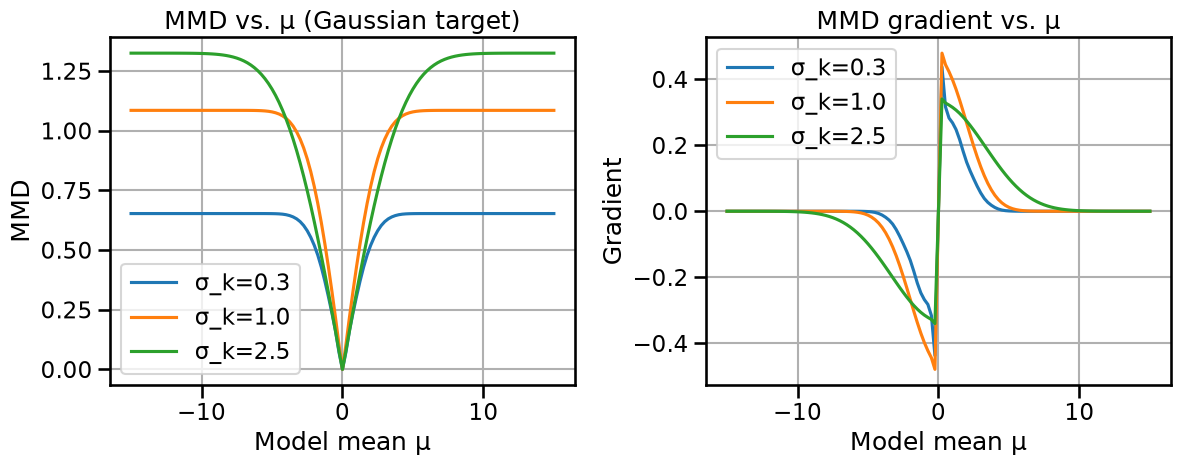

In [14]:
# MMD vs. μ for different kernel bandwidths
mu_values = np.linspace(-15.0, 15.0, 121)
bandwidths = [0.3, 1.0, 2.5]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for bw in bandwidths:
    metrics, grads = evaluate_metric_curve(
        mu_values,
        lambda mu, bw=bw: maximum_mean_discrepancy(mu, TARGETS["gaussian"], model_std=1.0, bandwidth=bw),
    )
    axes[0].plot(mu_values, metrics, label=f"σ_k={bw}")
    axes[1].plot(mu_values, grads, label=f"σ_k={bw}")

axes[0].set_title("MMD vs. μ (Gaussian target)")
axes[0].set_xlabel("Model mean μ")
axes[0].set_ylabel("MMD")
axes[0].legend()

axes[1].set_title("MMD gradient vs. μ")
axes[1].set_xlabel("Model mean μ")
axes[1].set_ylabel("Gradient")
axes[1].legend()

fig.tight_layout()
plt.show()


::: {.callout-tip appearance="default"}
### Experiment: Effect of MMD Kernel Bandwidth
- Which bandwidth reacts most strongly to small shifts in $\mu$?  
- Observe how the gradient flattens for large $\sigma_k$. When might that be desirable?  
- How would you select $\sigma_k$ automatically in a learning system?
:::


In [ ]:
# Interactive MMD explorer
if widgets is None:
    maybe_display(None)
else:
    mmd_target_dropdown = widgets.Dropdown(
        options=[(spec.name, key) for key, spec in TARGETS.items()],
        value="gaussian",
        description="Target",
        style={"description_width": "initial"},
    )
    mmd_mu_slider = widgets.FloatSlider(value=0.0, min=-15.0, max=15.0, step=0.5, description="μ")
    mmd_std_slider = widgets.FloatSlider(value=1.0, min=0.5, max=2.5, step=0.1, description="σ_q")
    mmd_bw_slider = widgets.FloatLogSlider(value=1.0, base=10, min=-1, max=1, step=0.05, description="σ_k")
    mmd_output = widgets.Output()

    def _update_mmd(*_):
        with mmd_output:
            mmd_output.clear_output(wait=True)
            target = TARGETS[mmd_target_dropdown.value]
            mu_val = torch.tensor(mmd_mu_slider.value, dtype=DEFAULT_DTYPE, device=device, requires_grad=True)
            std_val = float(mmd_std_slider.value)
            bw_val = float(mmd_bw_slider.value)
            mmd_val = maximum_mean_discrepancy(mu_val, target, model_std=std_val, bandwidth=bw_val)
            grad = torch.autograd.grad(mmd_val, mu_val)[0].detach().cpu().item()

            mu_values = np.linspace(mmd_mu_slider.min, mmd_mu_slider.max, 181)
            metrics_curve, grads_curve = evaluate_metric_curve(
                mu_values,
                lambda mu: maximum_mean_discrepancy(mu, target, model_std=std_val, bandwidth=bw_val),
            )

            target_pdf = get_target_pdf(target)
            model_pdf = gaussian_pdf_torch(GRID_X, mmd_mu_slider.value, std_val)

            grid_np = GRID_X.cpu().numpy()
            target_np = target_pdf.cpu().numpy()
            model_np = model_pdf.cpu().numpy()

            fig, axes = plt.subplots(1, 3, figsize=(18, 4))

            axes[0].plot(grid_np, target_np, label=target.name, linewidth=2)
            axes[0].plot(grid_np, model_np, label=f"Model μ={mmd_mu_slider.value:.1f}, σ={std_val:.1f}", linestyle="--", linewidth=2)
            axes[0].set_title("Density comparison")
            axes[0].set_xlabel("x")
            axes[0].set_ylabel("Density")
            axes[0].set_xlim(*PLOT_XLIM)
            axes[0].legend()

            axes[1].plot(mu_values, metrics_curve, color="tab:blue", linewidth=2)
            axes[1].axvline(mmd_mu_slider.value, color="black", linestyle=":")
            axes[1].scatter([mmd_mu_slider.value], [mmd_val.detach().cpu().item()], color="tab:blue")
            axes[1].set_title("MMD vs. μ")
            axes[1].set_xlabel("Model mean μ")
            axes[1].set_ylabel("MMD")

            axes[2].plot(mu_values, grads_curve, color="tab:red", linewidth=2)
            axes[2].axhline(0.0, color="black", linestyle=":")
            axes[2].axvline(mmd_mu_slider.value, color="black", linestyle=":")
            axes[2].scatter([mmd_mu_slider.value], [grad], color="tab:red")
            axes[2].set_title("Gradient d(MMD)/dμ")
            axes[2].set_xlabel("Model mean μ")
            axes[2].set_ylabel("Gradient")

            fig.suptitle(
                f"MMD = {mmd_val.detach().cpu().item():.3f} | Gradient = {grad:.3f}",
                fontsize=14,
            )
            fig.tight_layout()
            plt.show()

    for control in (mmd_target_dropdown, mmd_mu_slider, mmd_std_slider, mmd_bw_slider):
        control.observe(_update_mmd, names="value")

    _update_mmd()
    maybe_display(
        widgets.VBox(
            [
                widgets.HTML("<h4>Interactive MMD Explorer</h4>"),
                mmd_target_dropdown,
                mmd_mu_slider,
                mmd_std_slider,
                mmd_bw_slider,
                mmd_output,
            ]
        )
    )

## Optimal Transport (Wasserstein-2 Distance)
Optimal Transport (OT) frames distribution comparison as the problem of moving probability mass from a source distribution $q$ to a target distribution $p$ at minimal cost. Given a ground cost $c(x, y)$ measuring how expensive it is to transport mass from $x$ to $y$, the quadratic OT problem seeks a coupling $\pi(x, y)$ with marginals $q$ and $p$ that minimizes the total transport cost:
$$
W_2^2(p, q) = \inf_{\pi \in \Pi(p, q)} \int_{\mathbb{R}^d \times \mathbb{R}^d} \|x - y\|^2 \, d\pi(x, y),
$$
where $\Pi(p, q)$ denotes the set of joint distributions whose marginals are $p$ and $q$. This formulation differs from divergence-based distances above (KL, JS, MMD) because it explicitly models *where* probability mass must move, rather than comparing densities pointwise or via kernel similarities. As a result, OT remains informative even when supports do not overlap: the metric still reflects how far mass must travel to align the distributions.

In one dimension, the optimal coupling sorts both distributions and pairs quantiles. The squared Wasserstein-2 distance simplifies to
$$
W_2^2(p, q) = \int_0^1 \left|F_p^{-1}(u) - F_q^{-1}(u)\right|^2 \, du,
$$
with $F^{-1}$ denoting the quantile function. For Gaussians, this has a closed form $W_2^2 = (\mu_p - \mu)^2 + (\sigma_p - \sigma_q)^2$. We will compute it via quantile functions to keep the numerical pipeline consistent for non-Gaussian targets.

In [16]:
def gaussian_quantile(u: torch.Tensor, mean: float, std: float) -> torch.Tensor:
    mean_t = torch.as_tensor(mean, dtype=DEFAULT_DTYPE, device=device)
    std_t = torch.as_tensor(std, dtype=DEFAULT_DTYPE, device=device)
    return mean_t + std_t * math.sqrt(2.0) * torch.erfinv(2.0 * u - 1.0)


def wasserstein_2(
    mu: torch.Tensor,
    target: DistributionSpec,
    model_std: float = 1.0,
    sample_count: int = 1024,
) -> torch.Tensor:
    if "mean" in target.metadata and "std" in target.metadata:  # single Gaussian target: use closed form
        mu_p = target.metadata.get("mean", 0.0)
        sigma_p = target.metadata.get("std", 1.0)
        sigma_q = model_std
        diff_sq = (mu - mu_p) ** 2 + (sigma_q - sigma_p) ** 2
        return torch.sqrt(torch.clamp(diff_sq, min=0.0))

    # Empirical quantile-based estimate for non-Gaussian targets
    u = torch.linspace(0.0 + 0.5 / sample_count, 1.0 - 0.5 / sample_count, sample_count, dtype=DEFAULT_DTYPE, device=device)
    samples_p = torch.sort(sample_with_matching_noise(target, sample_count))[0]
    samples_q = torch.sort(mu + model_std * BASE_NOISE_NORMAL[:sample_count])[0]
    return torch.sqrt(torch.mean((samples_p - samples_q) ** 2))

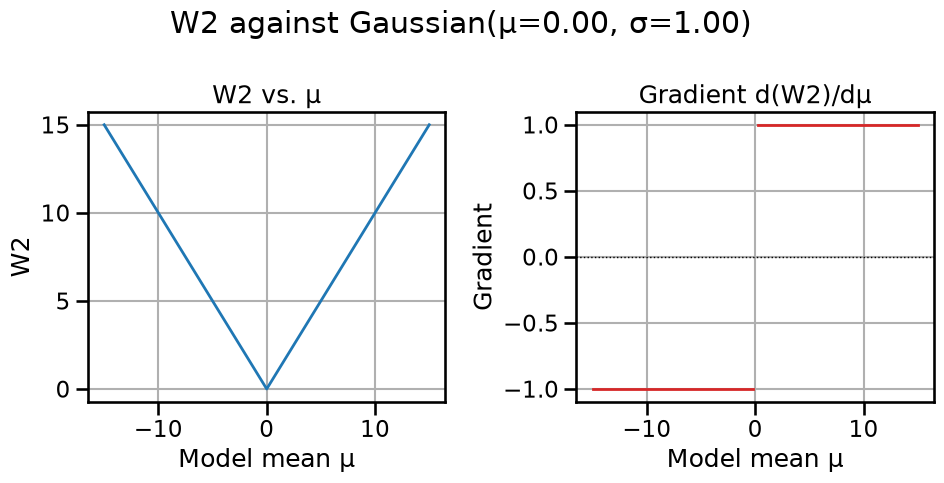

In [17]:
# Wasserstein-2 distance vs. μ for Gaussian target
mu_values = np.linspace(-15.0, 15.0, 121)
w2_metrics, w2_grads = evaluate_metric_curve(
    mu_values,
    lambda mu: wasserstein_2(mu, TARGETS["gaussian"], model_std=1.0),
)
plot_metric_and_gradient(mu_values, w2_metrics, w2_grads, metric_name="W2", target_desc=TARGETS["gaussian"].name)

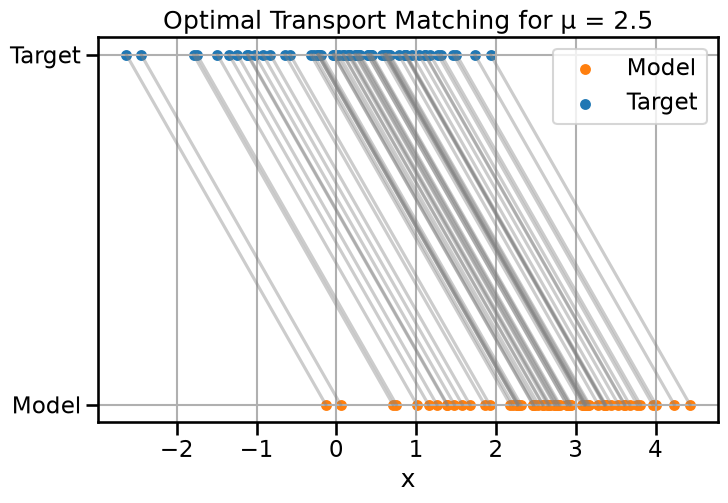

In [18]:
# Visualizing the optimal transport map in 1D
mu_demo = 2.5
sample_count = 64
u = torch.linspace(0.0 + 0.5 / sample_count, 1.0 - 0.5 / sample_count, sample_count, dtype=DEFAULT_DTYPE, device=device)
source_samples = torch.sort(mu_demo + BASE_NOISE_NORMAL[:sample_count])[0].cpu().numpy()
target_samples = torch.sort(sample_with_matching_noise(TARGETS["gaussian"], sample_count))[0].cpu().numpy()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(source_samples, np.zeros_like(source_samples), label="Model", color="tab:orange", s=40)
ax.scatter(target_samples, np.ones_like(target_samples), label="Target", color="tab:blue", s=40)
for xs, xt in zip(source_samples, target_samples):
    ax.plot([xs, xt], [0.0, 1.0], color="gray", alpha=0.4)
ax.set_title("Optimal Transport Matching for μ = 2.5")
ax.set_yticks([0, 1])
ax.set_yticklabels(["Model", "Target"])
ax.set_xlabel("x")
ax.legend()
plt.show()

::: {.callout-tip appearance="default"}
### Reflection: Transport as Matching
- How does the transport map change if you halve the model variance?  
- Compare the length of the transport lines with the Wasserstein distance you computed earlier.  
- What would happen if the target distribution had gaps (e.g., a mixture)? Sketch the expected matching pattern.
:::


In [19]:
# Interactive Wasserstein explorer
if widgets is None:
    maybe_display(None)
else:
    w2_target_dropdown = widgets.Dropdown(
        options=[(spec.name, key) for key, spec in TARGETS.items()],
        value="gaussian",
        description="Target",
        style={"description_width": "initial"},
    )
    w2_mu_slider = widgets.FloatSlider(value=0.0, min=-15.0, max=15.0, step=0.1, description="μ")
    w2_std_slider = widgets.FloatSlider(value=1.0, min=0.5, max=2.5, step=0.1, description="σ_q")
    w2_output = widgets.Output()

    def _update_w2(*_):
        with w2_output:
            w2_output.clear_output(wait=True)
            target = TARGETS[w2_target_dropdown.value]
            mu_val = torch.tensor(w2_mu_slider.value, dtype=DEFAULT_DTYPE, device=device, requires_grad=True)
            std_val = float(w2_std_slider.value)
            w2_val = wasserstein_2(mu_val, target, model_std=std_val)
            grad = torch.autograd.grad(w2_val, mu_val)[0].detach().cpu().item()

            mu_values = np.linspace(w2_mu_slider.min, w2_mu_slider.max, 181)
            metrics_curve, grads_curve = evaluate_metric_curve(
                mu_values,
                lambda mu: wasserstein_2(mu, target, model_std=std_val),
            )

            target_pdf = get_target_pdf(target)
            model_pdf = gaussian_pdf_torch(GRID_X, w2_mu_slider.value, std_val)

            grid_np = GRID_X.cpu().numpy()
            target_np = target_pdf.cpu().numpy()
            model_np = model_pdf.cpu().numpy()

            fig, axes = plt.subplots(1, 3, figsize=(18, 4))

            axes[0].plot(grid_np, target_np, label=target.name, linewidth=2)
            axes[0].plot(grid_np, model_np, label=f"Model μ={w2_mu_slider.value:.1f}, σ={std_val:.1f}", linestyle="--", linewidth=2)
            axes[0].set_title("Density comparison")
            axes[0].set_xlabel("x")
            axes[0].set_ylabel("Density")
            axes[0].set_xlim(*PLOT_XLIM)
            axes[0].legend()

            axes[1].plot(mu_values, metrics_curve, color="tab:blue", linewidth=2)
            axes[1].axvline(w2_mu_slider.value, color="black", linestyle=":")
            axes[1].scatter([w2_mu_slider.value], [w2_val.detach().cpu().item()], color="tab:blue")
            axes[1].set_title("Wasserstein-2 vs. μ")
            axes[1].set_xlabel("Model mean μ")
            axes[1].set_ylabel("W2 distance")

            axes[2].plot(mu_values, grads_curve, color="tab:red", linewidth=2)
            axes[2].axhline(0.0, color="black", linestyle=":")
            axes[2].axvline(w2_mu_slider.value, color="black", linestyle=":")
            axes[2].scatter([w2_mu_slider.value], [grad], color="tab:red")
            axes[2].set_title("Gradient d(W2)/dμ")
            axes[2].set_xlabel("Model mean μ")
            axes[2].set_ylabel("Gradient")

            fig.suptitle(
                f"W2 = {w2_val.detach().cpu().item():.3f} | Gradient = {grad:.3f}",
                fontsize=14,
            )
            fig.tight_layout()
            plt.show()

            # Snapshot of the transport plan: sort both sample sets and match them quantile by quantile
            transport_samples = 80
            src = torch.sort(mu_val.detach() + std_val * BASE_NOISE_NORMAL[:transport_samples])[0].cpu().numpy()
            tgt = torch.sort(sample_with_matching_noise(target, transport_samples))[0].cpu().numpy()
            fig_map, ax_map = plt.subplots(figsize=(8, 4))
            ax_map.scatter(src, np.zeros_like(src), label="Model", color="tab:orange", s=25)
            ax_map.scatter(tgt, np.ones_like(tgt), label="Target", color="tab:blue", s=25)
            for xs, xt in zip(src, tgt):
                ax_map.plot([xs, xt], [0.0, 1.0], color="gray", alpha=0.3)
            ax_map.set_yticks([0, 1])
            ax_map.set_yticklabels(["Model", "Target"])
            ax_map.set_xlabel("x")
            ax_map.set_title("Transport plan snapshot")
            fig_map.tight_layout()
            plt.show()

    for control in (w2_target_dropdown, w2_mu_slider, w2_std_slider):
        control.observe(_update_w2, names="value")

    _update_w2()
    maybe_display(widgets.VBox([widgets.HTML("<h4>Interactive Wasserstein Explorer</h4>"), w2_target_dropdown, w2_mu_slider, w2_std_slider, w2_output]))

## Wrap-Up
We inspected five prominent distribution distances, paying attention to the gradients they induce for a simple Gaussian parameter. Key takeaways:
- KL divergences emphasize support mismatch and can be asymmetric in how they penalize missing mass.
- JS divergence softens gradients and stays bounded, making it attractive for adversarial training.
- MMD exposes the role of kernel bandwidth in shaping sensitivity to local vs. global structure.
- Wasserstein distance reasons about mass transport and yields interpretable gradient flows.


## Exercises

The exercises reuse the distributions and the distance functions defined in this chapter (`TARGETS`, `forward_kl`, `reverse_kl`, `jensen_shannon`, `maximum_mean_discrepancy`, `wasserstein_2` and the helper `evaluate_metric_curve`), so run the chapter's cells first. 

::: {.callout-note appearance="simple" icon=false}

### Exercise 1 (~5 min): Five distances, four properties
This chapter introduced five ways of measuring how far apart two distributions are: the forward Kullback-Leibler (KL) divergence $\mathrm{KL}(p\,\parallel\,q)$, the reverse KL divergence $\mathrm{KL}(q\,\parallel\,p)$, the Jensen-Shannon (JS) divergence, the maximum mean discrepancy (MMD) with the radial basis function kernel, and the Wasserstein-2 distance $W_2$. The four properties in the table are: symmetric in $p$ and $q$; bounded above by a constant that does not depend on $p$ or $q$; finite when the supports of $p$ and $q$ do not overlap; and a true metric (symmetric, zero only when $p = q$, and satisfying the triangle inequality).

| Distance | Symmetric | Bounded | Finite for non-overlapping supports | True metric |
|---|---|---|---|---|
| Forward KL | ? | ? | ? | ? |
| Reverse KL | ? | ? | ? | ? |
| Jensen-Shannon | ? | ? | ? | ? |
| MMD (RBF kernel) | ? | ? | ? | ? |
| Wasserstein-2 | ? | ? | ? | ? |

- (a) Replace each ? with *yes* or *no*, and give a one-line reason for each entry.
- (b) Pick two entries of your table and check them numerically with the chapter's functions, for example by evaluating a divergence in both directions for $p(x) = \mathcal{N}(x;\, 0, 1)$ and $q(x) = \mathcal{N}(x;\, 1.5, 0.5^2)$, or by sweeping $\mu$ out to $\pm 15$ and looking at the largest value a divergence reaches. Why can a numerical check of this kind only ever confirm a *no* in the table and never prove a *yes*?

:::

In [20]:
# You can use this code cell for this exercise, if you like.

---

Run the cell below to produce the figure for Exercise 2. It draws the chapter's bimodal mixture target $p(x)$ (shaded) together with six candidate models $q(x)$ (dashed), each a single Gaussian with its own mean and width, and prints the parameters of each candidate.

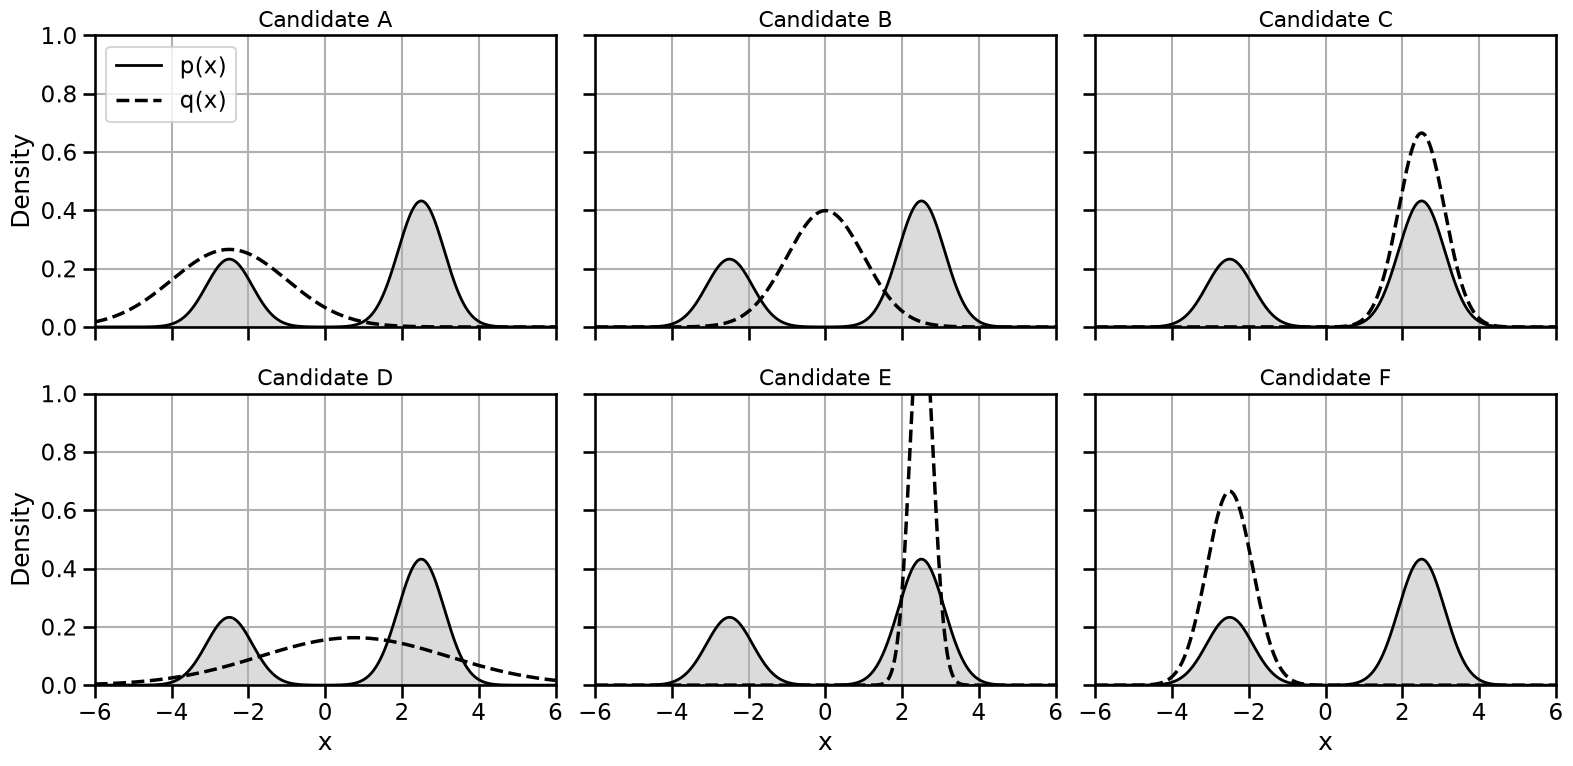

Candidate A: mu = -2.50, sigma = 1.50
Candidate B: mu =  0.00, sigma = 1.00
Candidate C: mu =  2.50, sigma = 0.60
Candidate D: mu =  0.75, sigma = 2.45
Candidate E: mu =  2.50, sigma = 0.30
Candidate F: mu = -2.50, sigma = 0.60


In [21]:
#| echo: false
# Exercise 2 figure: six single-Gaussian candidates q(x) against the bimodal mixture target.
EX2_TARGET = TARGETS["gaussian_mixture"]
EX2_CANDIDATES = {                 # letter: (mu, sigma)
    "A": (-2.5, 1.5),
    "B": (0.0, 1.0),
    "C": (2.5, 0.6),
    "D": (0.75, 2.45),
    "E": (2.5, 0.3),
    "F": (-2.5, 0.6),
}

with torch.no_grad():
    ex2_grid = GRID_X.cpu().numpy()
    ex2_target_pdf = EX2_TARGET.pdf(GRID_X).cpu().numpy()

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True, sharey=True)
for ax, (letter, (mu_c, sigma_c)) in zip(axes.ravel(), EX2_CANDIDATES.items()):
    with torch.no_grad():
        ex2_candidate_pdf = gaussian_pdf_torch(GRID_X, mu_c, sigma_c).cpu().numpy()
    ax.fill_between(ex2_grid, ex2_target_pdf, color="lightgray", alpha=0.8)
    ax.plot(ex2_grid, ex2_target_pdf, color="black", linewidth=2, label="p(x)")
    ax.plot(ex2_grid, ex2_candidate_pdf, color="black", linestyle="--", linewidth=2.5, label="q(x)")
    ax.set_title(f"Candidate {letter}", fontsize=16)
    ax.set_xlim(*PLOT_XLIM)
    ax.set_ylim(0.0, 1.0)
for ax in axes[1]:
    ax.set_xlabel("x")
for ax in axes[:, 0]:
    ax.set_ylabel("Density")
axes[0, 0].legend(loc="upper left")
fig.tight_layout()
plt.show()

for letter, (mu_c, sigma_c) in EX2_CANDIDATES.items():
    print(f"Candidate {letter}: mu = {mu_c:5.2f}, sigma = {sigma_c:4.2f}")

::: {.callout-note appearance="simple" icon=false}
### Exercise 2 (~8 min): Which fit has the lowest reverse KL?
The target is the chapter's mixture $p(x) = 0.35\,\mathcal{N}(x;\, -2.5, 0.6^2) + 0.65\,\mathcal{N}(x;\, 2.5, 0.6^2)$ and each candidate is a single Gaussian
$$
q(x) = \mathcal{N}(x;\, \mu, \sigma^2) = \frac{1}{\sigma\sqrt{2\pi}} \exp\!\left(-\frac{(x-\mu)^2}{2\sigma^2}\right).
$$
Suppose we had to pick one of the six candidates by minimizing the reverse KL divergence $\mathrm{KL}(q\,\parallel\,p) = \int q(x) \log \frac{q(x)}{p(x)}\,dx$. The only extra fact you need is the entropy of $q$, $H(q) = -\int q(x) \log q(x)\,dx$, which for a Gaussian equals $\tfrac{1}{2}\log(2\pi e\,\sigma^2)$, so that $\mathrm{KL}(q\,\parallel\,p) = -H(q) - \mathbb{E}_{q}[\log p(x)]$.

- (a) Before computing anything, rank the six candidates from lowest to highest reverse KL by reasoning about where each $q$ puts its mass and what $p$ looks like there. Which candidate wins, and why?
- (b) Now compute both $\mathrm{KL}(p\,\parallel\,q)$ and $\mathrm{KL}(q\,\parallel\,p)$ for all six candidates with `forward_kl` and `reverse_kl` (both take the candidate's width through `model_std`; the parameters are in `EX2_CANDIDATES`). Where does the computation disagree with your ranking, and what did you misjudge?
- (c) The broadest candidate has the lowest forward KL and one of the highest reverse KLs. Why does the same $q(x)$ win under one direction and lose under the other?
- (d) Two candidates have exactly the width of a mode, one on the taller mode and one on the smaller mode. Why does the one on the taller mode have the lower reverse KL, and what sets the size of the difference between the two?
- (e) The candidate that is narrower than the mode it sits on loses to the candidate that has the mode's width, even though it is "more confident". Which term of $\mathrm{KL}(q\,\parallel\,p) = -H(q) - \mathbb{E}_{q}[\log p(x)]$ penalizes it, and why?
- (f) Suppose these were not toy densities but a generative model being trained on data that contain two distinct families of designs. What would a model trained by minimizing forward KL produce, what would one trained by minimizing reverse KL produce, and why?
:::

In [22]:
# You can use this code cell for this exercise, if you like.

---

::: {.callout-note appearance="simple" icon=false}
### Exercise 3 (~5 min): Flat divergences, flat gradients
Go back to the chapter's figure that compares the forward KL and the JS divergence for the standard normal target $p(x) = \mathcal{N}(x;\, 0, 1)$ as the model mean $\mu$ sweeps from $-15$ to $15$ (the cell that defines `js_metrics` and `js_grads`): the two left panels show the divergences on their own axes, and the right panel shows the magnitudes of their gradients on a logarithmic axis.

- (a) Beyond roughly which $|\mu|$ is the JS divergence flat, and at what value does it sit there? Why does it stop growing even though the two distributions keep moving apart?
- (b) Read the two gradient magnitudes at $\mu = 10$ off the right panel, or compute them with `evaluate_metric_curve`. By roughly how many orders of magnitude do they differ, and why?
- (c) Imagine a model whose initial guess is far from the data, say $\mu = 10$. Describe what the first few gradient steps look like under each of the two losses, and why. (This is the situation a generative adversarial network, whose loss is closely related to the JS divergence, finds itself in at the start of training; we will return to it in Part 2.)
:::

---

Run the cell below to produce the figure for Exercise 4. The top panel shows the two distributions being compared, $P$ and $Q$, with the chapter's samples from each. The four panels below are candidate curves of the MMD between $P$ and $Q$ as a function of the kernel bandwidth $\sigma_k$ (note the logarithmic axis); only one of them is the real curve.

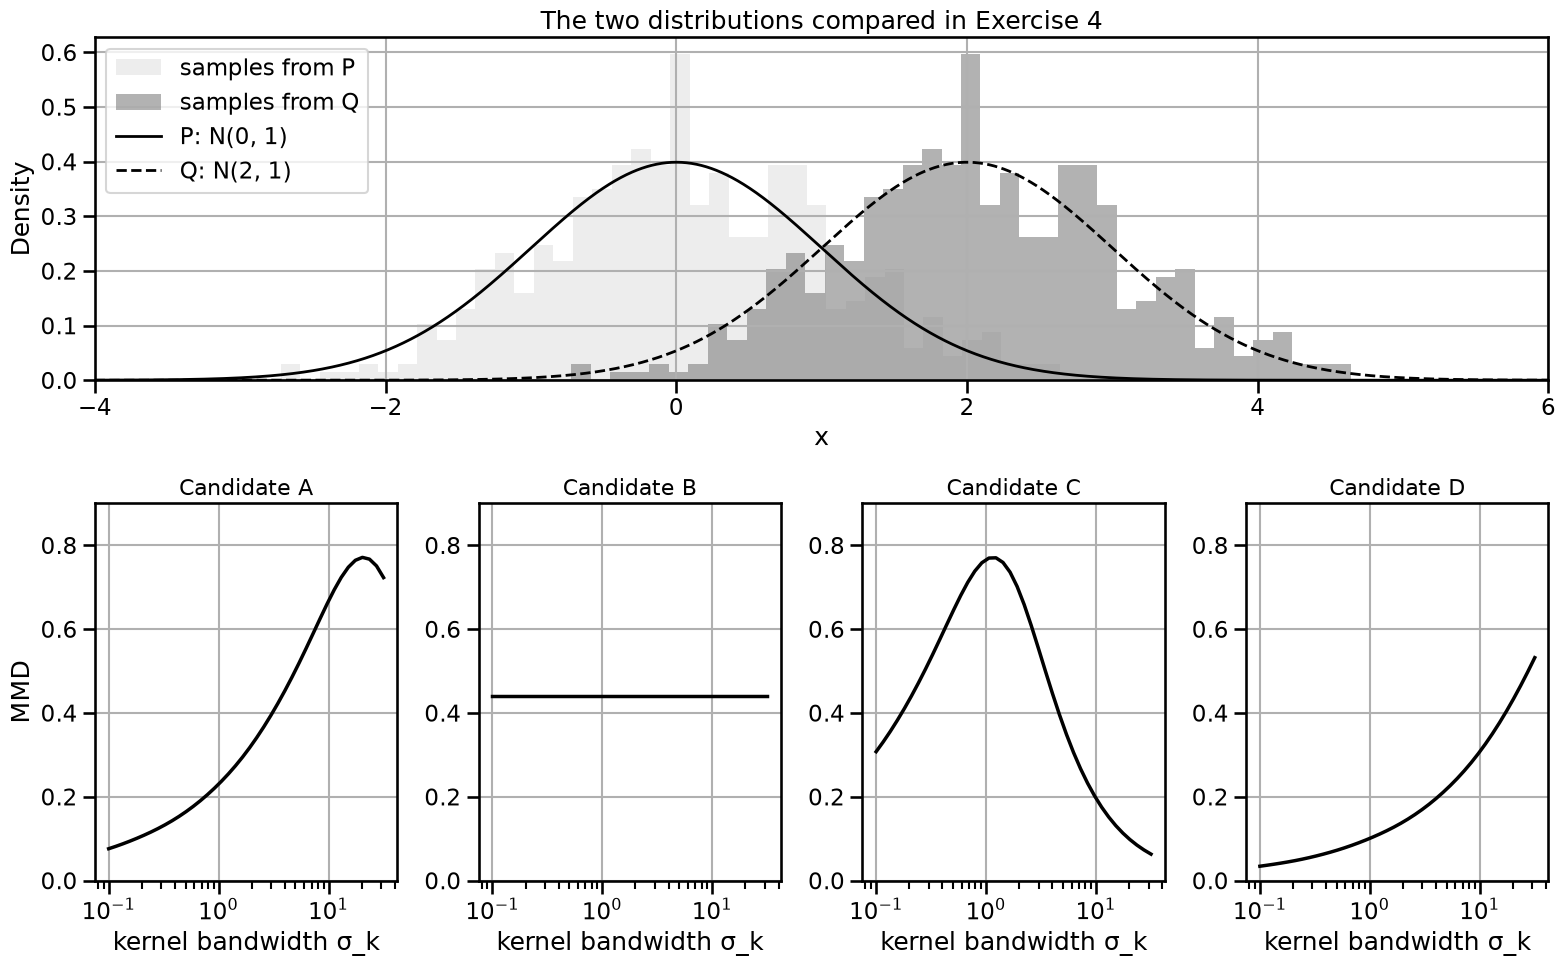

In [23]:
#| echo: false
# Exercise 4 figure: the real MMD-versus-bandwidth curve for N(0,1) against N(2,1) and three impostors.
EX4_TARGET = TARGETS["gaussian"]
EX4_MU_Q = 2.0
EX4_BANDWIDTHS = np.logspace(-1.0, 1.5, 40)
EX4_SAMPLE_COUNT = 512


def ex4_mmd_curve(bandwidths: np.ndarray) -> np.ndarray:
    """MMD between the chapter's N(0,1) samples and N(2,1) samples for each bandwidth."""
    with torch.no_grad():
        return np.array([
            maximum_mean_discrepancy(torch.tensor(EX4_MU_Q, dtype=DEFAULT_DTYPE, device=device), EX4_TARGET,
                                     model_std=1.0, bandwidth=float(bw), sample_count=EX4_SAMPLE_COUNT).item()
            for bw in bandwidths
        ])


ex4_true_curve = ex4_mmd_curve(EX4_BANDWIDTHS)
EX4_CURVES = {
    "A": ex4_mmd_curve(EX4_BANDWIDTHS / 18.0),          # the real shape, shifted to a much larger bandwidth
    "B": np.full_like(ex4_true_curve, ex4_true_curve.mean()),   # flat
    "C": ex4_true_curve,                                 # the real curve
    "D": ex4_mmd_curve(EX4_BANDWIDTHS / 100.0),         # rising through the whole window
}

with torch.no_grad():
    ex4_samples_p = sample_with_matching_noise(EX4_TARGET, EX4_SAMPLE_COUNT).cpu().numpy()
    ex4_samples_q = (EX4_MU_Q + BASE_NOISE_NORMAL[:EX4_SAMPLE_COUNT]).cpu().numpy()
    ex4_grid = GRID_X.cpu().numpy()
    ex4_pdf_p = EX4_TARGET.pdf(GRID_X).cpu().numpy()
    ex4_pdf_q = gaussian_pdf_torch(GRID_X, EX4_MU_Q, 1.0).cpu().numpy()

fig = plt.figure(figsize=(16, 10))
gs = GridSpec(2, 4, figure=fig, height_ratios=[1.0, 1.1])
ax_top = fig.add_subplot(gs[0, :])
ax_top.hist(ex4_samples_p, bins=40, density=True, alpha=0.4, color="lightgray", label="samples from P")
ax_top.hist(ex4_samples_q, bins=40, density=True, alpha=0.6, color="gray", label="samples from Q")
ax_top.plot(ex4_grid, ex4_pdf_p, color="black", linewidth=2, label="P: N(0, 1)")
ax_top.plot(ex4_grid, ex4_pdf_q, color="black", linewidth=2, linestyle="--", label="Q: N(2, 1)")
ax_top.set_xlim(-4.0, 6.0)
ax_top.set_xlabel("x")
ax_top.set_ylabel("Density")
ax_top.set_title("The two distributions compared in Exercise 4")
ax_top.legend(loc="upper left")
for k, (letter, curve) in enumerate(EX4_CURVES.items()):
    ax = fig.add_subplot(gs[1, k])
    ax.semilogx(EX4_BANDWIDTHS, curve, color="black", linewidth=2.5)
    ax.set_ylim(0.0, 0.9)
    ax.set_title(f"Candidate {letter}", fontsize=16)
    ax.set_xlabel("kernel bandwidth σ_k")
    if k == 0:
        ax.set_ylabel("MMD")
fig.tight_layout()
plt.show()

::: {.callout-note appearance="simple" icon=false}
### Exercise 4 (~5 min): Predict the MMD curve
The two distributions are $P(x) = \mathcal{N}(x;\, 0, 1)$ and $Q(x) = \mathcal{N}(x;\, 2, 1)$, with the same number of samples from each, and the MMD uses the chapter's radial basis function kernel $k_\sigma(x, y) = \exp\!\left(-\tfrac{(x - y)^2}{2\sigma_k^2}\right)$ for bandwidths $\sigma_k$ between $0.1$ and about $30$.

- (a) Pick the real curve by reasoning and say why each of the other three cannot be right.
- (b) Explain both tails from the kernel formula. What do all the pairwise similarities $k_\sigma(x, y)$ look like when $\sigma_k$ is much smaller than the typical distance between samples, and when it is much larger? What does each situation do to the three terms of $\mathrm{MMD}^2$?
- (c) For *any* pair of distributions, what does the MMD return when the bandwidth is far larger than every distance between samples? Why is this not a flaw in the formula, and what does it tell you about choosing $\sigma_k$ in practice?
:::

---

The next exercise looks at a target and a model whose supports do not overlap. Run the cell below to build them: the target is uniform on $[-3, -1]$ and the model is the usual Gaussian $q(x) = \mathcal{N}(x;\, \mu, 1)$, placed at $\mu = 3$. Feel free to read the code and to move the model around.

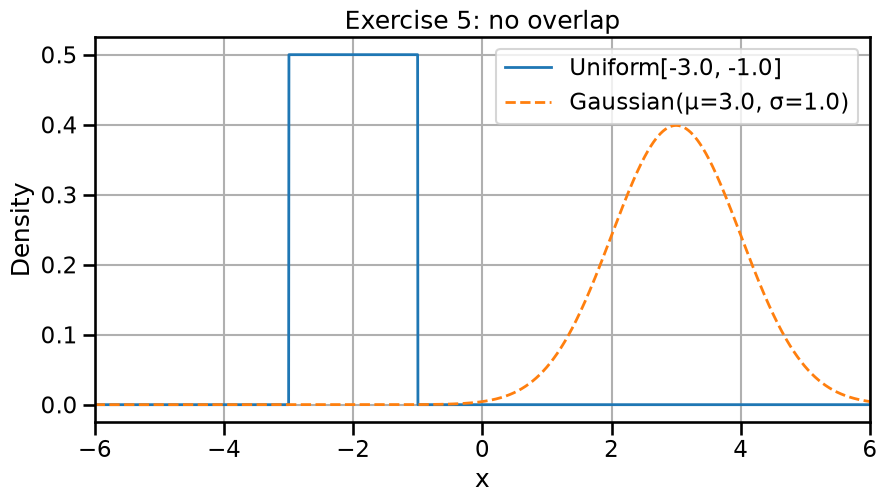

In [24]:
# Exercise 5 setup: a target and a model that do not overlap
EX5_TARGET = make_uniform(low=-3.0, high=-1.0)
EX5_MU = 3.0            # you can move the model around, e.g. 1.0 or -1.5
EX5_MODEL_STD = 1.0

with torch.no_grad():
    ex5_target_pdf = EX5_TARGET.pdf(GRID_X)
    ex5_model_pdf = gaussian_pdf_torch(GRID_X, EX5_MU, EX5_MODEL_STD)
plot_distribution_pair(GRID_X, ex5_target_pdf, ex5_model_pdf, title="Exercise 5: no overlap",
                       target_label=EX5_TARGET.name, model_label=f"Gaussian(μ={EX5_MU:.1f}, σ={EX5_MODEL_STD:.1f})")

::: {.callout-note appearance="simple" icon=false}
### Exercise 5 (~8 min): Supports that do not overlap
The target density is $p(x) = \tfrac{1}{2}$ for $-3 \le x \le -1$ and $0$ elsewhere, and the model is $q(x) = \mathcal{N}(x;\, \mu, 1)$ with $\mu = 3$, so that essentially all of the model's mass sits where the $p(x)$ has no support. Think of this as the first step of training: the model has to find its way to the data, and all it has is a distance and its gradient with respect to $\mu$. We look at four of the chapter's distances here: the forward KL $\mathrm{KL}(p\,\parallel\,q)$, the reverse KL $\mathrm{KL}(q\,\parallel\,p)$, the Jensen-Shannon divergence, and the MMD with the chapter's three bandwidths ($0.3$, $1.0$ and $2.5$).

- (a) Before computing anything, predict for each of them (counting the three MMD bandwidths separately) whether its value is finite and whether its gradient with respect to $\mu$ is usable, meaning that it points toward the data with a magnitude that reflects how far away they are. Give a reason for each prediction.
- (b) Compute the forward KL, the reverse KL, the JS divergence and the three MMDs, together with their gradients with respect to $\mu$ at $\mu = 3$, using the chapter's functions and `torch.autograd.grad` the way `evaluate_metric_curve` does. Which of your predictions were wrong, and why?
- (c) Rank them by how useful their gradient would be for moving the model toward the target, and defend the ranking. Why do the values of the distances tell a different story from their gradients?
- (d) Some of the values are infinite in spirit even though the code returns a finite number, and some gradients are zero or almost zero. What is each of them telling you about this pair of distributions, and what in the chapter's implementation keeps the values finite?
:::

In [25]:
# You can use this code cell for this exercise, if you like.